## Step 1: Environment & Model Loading

## What we do: Import necessary libraries (shap, xgboost, pandas) and load our trained XGBoost model along with the test dataset (X_test).
## Why we do it: To establish the workspace and ensure we have access to the trained model weights and data required for explanation.

In [6]:
import shap
import xgboost as xgb
import pandas as pd
import matplotlib.pyplot as plt
import joblib

# Load saved model and test data from disk
model = joblib.load('xgboost_fraud_model.pkl')
X_test = joblib.load('X_test.pkl')

print("Model loaded successfully:", type(model))
print("X_test shape loaded:", X_test.shape)

Model loaded successfully: <class 'xgboost.sklearn.XGBClassifier'>
X_test shape loaded: (554082, 9)


## Step 2: Initialize SHAP Explainer & Calculate Values

In [9]:
# Initialize SHAP TreeExplainer for the XGBoost model
explainer = shap.TreeExplainer(model)

# Calculate SHAP values for a subset of test data (e.g., 5,000 rows for performance)
sample_size = min(5000, len(X_test))
shap_values = explainer(X_test.iloc[:sample_size])

print("SHAP values calculated successfully!")

SHAP values calculated successfully!


## Step 3: Global Feature Importance Visualization

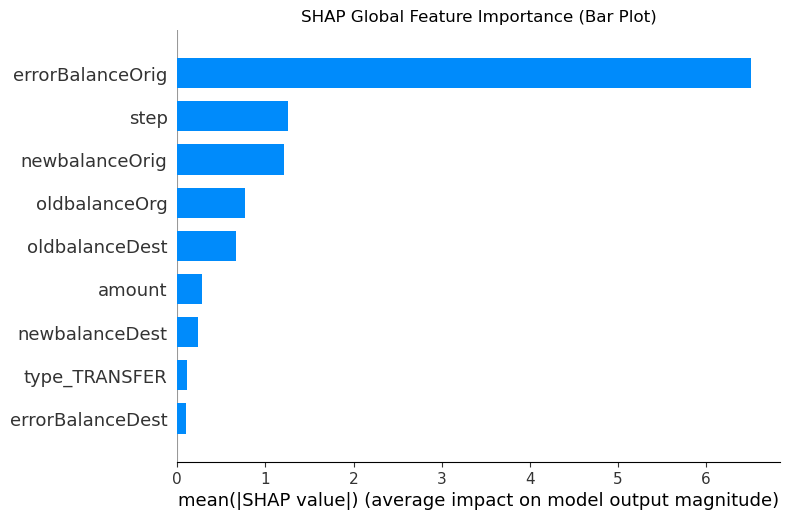

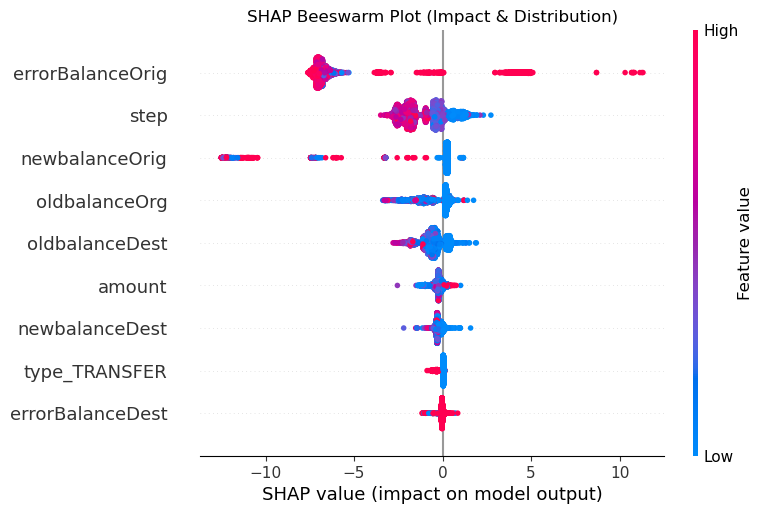

In [11]:
# 1. Global Feature Importance Bar Plot
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, X_test.iloc[:sample_size], plot_type="bar", show=False)
plt.title("SHAP Global Feature Importance (Bar Plot)")
plt.show()

# 2. Detailed Beeswarm Plot (Shows feature impact direction)
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, X_test.iloc[:sample_size], show=False)
plt.title("SHAP Beeswarm Plot (Impact & Distribution)")
plt.show()

## Step 4: Local Interpretability (Waterfall Plot for a Fraud Case)

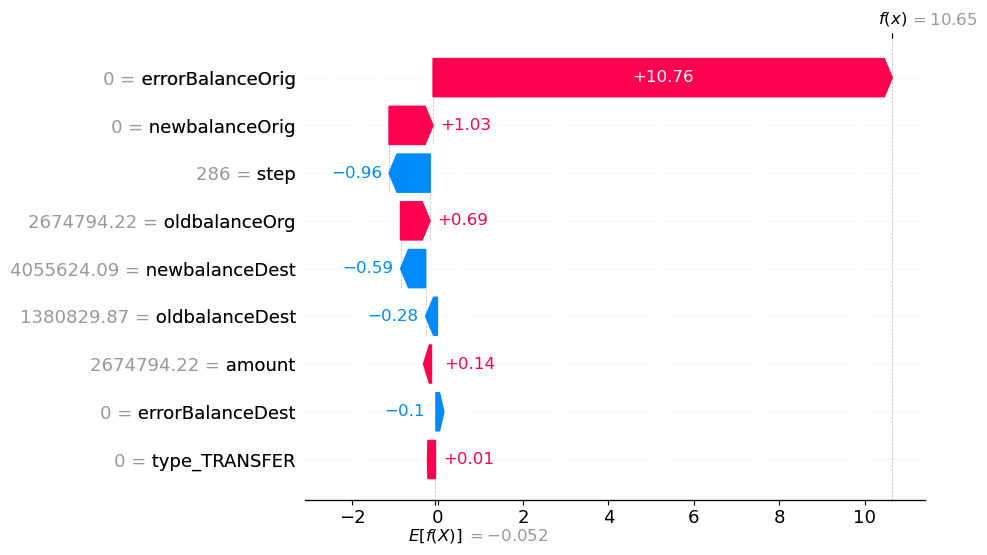

In [13]:
# Find a predicted fraud instance in the test sample
fraud_indices = [i for i, val in enumerate(model.predict(X_test.iloc[:sample_size])) if val == 1]

if fraud_indices:
    target_idx = fraud_indices[0] # Pick the first detected fraud case
    
    # Generate clean SHAP waterfall plot for the specific fraud transaction
    shap.plots.waterfall(shap_values[target_idx])
else:
    print("No fraud instances found in the current sample subset.")

## Step 5: Automated Compliance Incident Report

In [14]:
def generate_compliance_report(transaction_idx, X_data, s_values):
    """
    Generates a structured compliance incident report for a flagged transaction 
    based on local SHAP feature attributions.
    """
    print("=" * 60)
    print(f"REGULATORY COMPLIANCE INCIDENT REPORT - TRANSACTION INDEX: {transaction_idx}")
    print("=" * 60)
    print("STATUS: BLOCKED / HIGH-RISK FRAUD DETECTED\n")
    print("Top Risk Factors (SHAP Attribution Analysis):")
    
    local_shap = s_values[transaction_idx]
    vals = local_shap.values
    feature_names = X_data.columns
    
    # Sort features by absolute impact magnitude
    top_features_idx = sorted(range(len(vals)), key=lambda k: abs(vals[k]), reverse=True)[:3]
    
    for rank, idx in enumerate(top_features_idx, 1):
        feat_name = feature_names[idx]
        feat_val = X_data.iloc[transaction_idx][idx]
        impact = vals[idx]
        print(f" {rank}. Feature: '{feat_name}'")
        print(f"    - Actual Transaction Value: {feat_val}")
        print(f"    - Risk Impact Score (SHAP): {impact:+.4f}")
        
    print("=" * 60)
    print("Action Required: Forward to Anti-Fraud Investigation Team for SAR filing.\n")

# Execute report generation for our flagged transaction case
if fraud_indices:
    generate_compliance_report(target_idx, X_test, shap_values)

REGULATORY COMPLIANCE INCIDENT REPORT - TRANSACTION INDEX: 96
STATUS: BLOCKED / HIGH-RISK FRAUD DETECTED

Top Risk Factors (SHAP Attribution Analysis):
 1. Feature: 'errorBalanceOrig'
    - Actual Transaction Value: 0.0
    - Risk Impact Score (SHAP): +10.7578
 2. Feature: 'newbalanceOrig'
    - Actual Transaction Value: 0.0
    - Risk Impact Score (SHAP): +1.0320
 3. Feature: 'step'
    - Actual Transaction Value: 286.0
    - Risk Impact Score (SHAP): -0.9641
Action Required: Forward to Anti-Fraud Investigation Team for SAR filing.



/var/folders/9w/wwm516zj61551jlqwzcy7ch80000gn/T/ipykernel_2669/1947971422.py:21: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  feat_val = X_data.iloc[transaction_idx][idx]
